In [1]:
%pip install huggingface_hub pillow matplotlib pandas

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ------ --------------------------------- 1.3/8.2 MB 6.1 MB/s eta 0:00:02
   ------- -------------------------------- 1.6/8.2 MB 7.0 MB/s eta 0:00:01
   -------- ------------------------------- 1.8/8.2 MB 3.7 MB/s eta 0:00:02
   ------------ --------------------------- 2.6/8.2 MB 3.0 MB/s eta 0:00:02
   ----------------- ---------------------- 3.7/8.2 MB 3.4 MB/s eta 0:00:02
   ------------------------- -------------- 5.2/8.2 MB 4.1 MB/s eta 0:00:01
   --------------------------------- ------ 6.8/8.2 MB 4.6 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 4.8 MB/s  0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   -------------------------------- ------- 1.3/1.6 MB 13.4 MB/s eta 0:00:01
   ---------------------------------------- 1.6/1.6 MB 5.9 MB/s

In [2]:
from huggingface_hub import hf_hub_download

archive = hf_hub_download(
    repo_id="MCG-NJU/SportsMOT",
    repo_type="dataset",
    filename="dataset/train.tar",
    local_dir="../data/sportsmot_download"
)

print(archive)

dataset/train.tar: reconstructing file:   0%|          |  0.00B / 6.70GB            

dataset/train.tar: downloading bytes:           |  0.00B            

C:\Users\Manadip\OneDrive\Desktop\NVDIA\data\sportsmot_download\dataset\train.tar


In [9]:
import tarfile
with tarfile.open(archive, "r:") as tar:
    members =tar.getnames()

In [11]:
members[0:20]

['._train',
 'train',
 'train/._v_1LwtoLPw2TU_c016',
 'train/v_1LwtoLPw2TU_c016',
 'train/._v_Dk3EpDDa3o0_c007',
 'train/v_Dk3EpDDa3o0_c007',
 'train/._v_-6Os86HzwCs_c009',
 'train/v_-6Os86HzwCs_c009',
 'train/._v_-6Os86HzwCs_c007',
 'train/v_-6Os86HzwCs_c007',
 'train/._v_-6Os86HzwCs_c001',
 'train/v_-6Os86HzwCs_c001',
 'train/._v_4LXTUim5anY_c002',
 'train/v_4LXTUim5anY_c002',
 'train/._v_CW0mQbgYIF4_c005',
 'train/v_CW0mQbgYIF4_c005',
 'train/._v_iIxMOsCGH58_c013',
 'train/v_iIxMOsCGH58_c013',
 'train/._v_HdiyOtliFiw_c008',
 'train/v_HdiyOtliFiw_c008']

In [12]:
print("Total:",len(members))

Total: 57600


In [85]:
sequence = 'train/v_-6Os86HzwCs_c001'
sequence_members = [name for name in members
                    if name.startswith(sequence + "/img1/")]
print("Total:",len(sequence_members))


Total: 1650


In [50]:
print(sequence in members)

True


In [ ]:

print(sequence_members[:10])

['train/v_-6Os86HzwCs_c001/._gt', 'train/v_-6Os86HzwCs_c001/gt', 'train/v_-6Os86HzwCs_c001/._seqinfo.ini', 'train/v_-6Os86HzwCs_c001/seqinfo.ini', 'train/v_-6Os86HzwCs_c001/._img1', 'train/v_-6Os86HzwCs_c001/img1', 'train/v_-6Os86HzwCs_c001/img1/._000608.jpg', 'train/v_-6Os86HzwCs_c001/img1/000608.jpg', 'train/v_-6Os86HzwCs_c001/img1/._000634.jpg', 'train/v_-6Os86HzwCs_c001/img1/000634.jpg']


In [108]:
from pathlib import Path

image_files = sorted(
    [
        n for n in sequence_members
        if Path(n).name.endswith(".jpg")
        and not Path(n).name.startswith("._")
    ]
)[:20]

print("Selected frames:", len(image_files))
print(image_files[:5])

Selected frames: 20
['train/v_-6Os86HzwCs_c001/img1/000001.jpg', 'train/v_-6Os86HzwCs_c001/img1/000002.jpg', 'train/v_-6Os86HzwCs_c001/img1/000003.jpg', 'train/v_-6Os86HzwCs_c001/img1/000004.jpg', 'train/v_-6Os86HzwCs_c001/img1/000005.jpg']


In [109]:
print("Length:", len(image_files))


Length: 20


In [110]:
print(image_files[:20])

['train/v_-6Os86HzwCs_c001/img1/000001.jpg', 'train/v_-6Os86HzwCs_c001/img1/000002.jpg', 'train/v_-6Os86HzwCs_c001/img1/000003.jpg', 'train/v_-6Os86HzwCs_c001/img1/000004.jpg', 'train/v_-6Os86HzwCs_c001/img1/000005.jpg', 'train/v_-6Os86HzwCs_c001/img1/000006.jpg', 'train/v_-6Os86HzwCs_c001/img1/000007.jpg', 'train/v_-6Os86HzwCs_c001/img1/000008.jpg', 'train/v_-6Os86HzwCs_c001/img1/000009.jpg', 'train/v_-6Os86HzwCs_c001/img1/000010.jpg', 'train/v_-6Os86HzwCs_c001/img1/000011.jpg', 'train/v_-6Os86HzwCs_c001/img1/000012.jpg', 'train/v_-6Os86HzwCs_c001/img1/000013.jpg', 'train/v_-6Os86HzwCs_c001/img1/000014.jpg', 'train/v_-6Os86HzwCs_c001/img1/000015.jpg', 'train/v_-6Os86HzwCs_c001/img1/000016.jpg', 'train/v_-6Os86HzwCs_c001/img1/000017.jpg', 'train/v_-6Os86HzwCs_c001/img1/000018.jpg', 'train/v_-6Os86HzwCs_c001/img1/000019.jpg', 'train/v_-6Os86HzwCs_c001/img1/000020.jpg']


## Load images into memory 

In [111]:
from PIL import Image
images = []

with tarfile.open(archive,"r") as tar:
    for i in image_files[:20]:
        img = tar.extractfile(i)
        image = Image.open(img).convert("RGB")
        images.append(image)
print(f"loaded {len(images)} frames")


loaded 20 frames


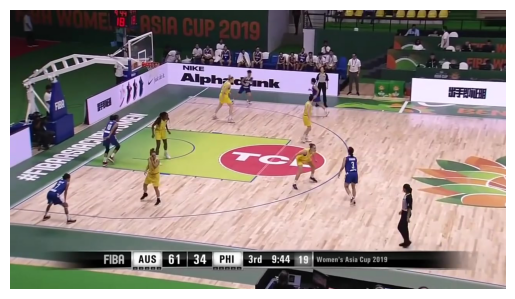

In [112]:
import matplotlib.pyplot as plt
plt.imshow(images[0])
plt.axis("off")
plt.show()